In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    RocCurveDisplay
)
from sklearn.dummy import DummyClassifier


In [3]:
df = pd.read_csv('xAPI-Edu-Data.csv')

df.head()

,gender,NationalITy,PlaceofBirth,StageID,GradeID,SectionID,Topic,Semester,Relation,raisedhands,VisITedResources,AnnouncementsView,Discussion,ParentAnsweringSurvey,ParentschoolSatisfaction,StudentAbsenceDays,Class
0,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,15,16,2,20,Yes,Good,Under-7,M
1,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,20,20,3,25,Yes,Good,Under-7,M
2,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,10,7,0,30,No,Bad,Above-7,L
3,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,30,25,5,35,No,Bad,Above-7,L
4,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,40,50,12,50,No,Bad,Above-7,M


In [4]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nData Types:")
print(df.dtypes)

print("\nSummary Statistics:")
display(df.describe(include='all'))

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (480, 17)

First 5 Records:


,gender,NationalITy,PlaceofBirth,StageID,GradeID,SectionID,Topic,Semester,Relation,raisedhands,VisITedResources,AnnouncementsView,Discussion,ParentAnsweringSurvey,ParentschoolSatisfaction,StudentAbsenceDays,Class
0,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,15,16,2,20,Yes,Good,Under-7,M
1,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,20,20,3,25,Yes,Good,Under-7,M
2,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,10,7,0,30,No,Bad,Above-7,L
3,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,30,25,5,35,No,Bad,Above-7,L
4,M,KW,KuwaIT,lowerlevel,G-04,A,IT,F,Father,40,50,12,50,No,Bad,Above-7,M



Data Types:
gender                      object
NationalITy                 object
PlaceofBirth                object
StageID                     object
GradeID                     object
SectionID                   object
Topic                       object
Semester                    object
Relation                    object
raisedhands                  int64
VisITedResources             int64
AnnouncementsView            int64
Discussion                   int64
ParentAnsweringSurvey       object
ParentschoolSatisfaction    object
StudentAbsenceDays          object
Class                       object
dtype: object

Summary Statistics:


,gender,NationalITy,PlaceofBirth,StageID,GradeID,SectionID,Topic,Semester,Relation,raisedhands,VisITedResources,AnnouncementsView,Discussion,ParentAnsweringSurvey,ParentschoolSatisfaction,StudentAbsenceDays,Class
count,480,480,480,480,480,480,480,480,480,480.000000,480.000000,480.000000,480.000000,480,480,480,480
unique,2,14,14,3,10,3,12,2,2,NaN,NaN,NaN,NaN,2,2,2,3
top,M,KW,KuwaIT,MiddleSchool,G-02,A,IT,F,Father,NaN,NaN,NaN,NaN,Yes,Good,Under-7,M
freq,305,179,180,248,147,283,95,245,283,NaN,NaN,NaN,NaN,270,292,289,211
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,46.775000,54.797917,37.918750,43.283333,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.779223,33.080007,26.611244,27.637735,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,1.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.750000,20.000000,14.000000,20.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50.000000,65.000000,33.000000,39.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,75.000000,84.000000,58.000000,70.000000,NaN,NaN,NaN,NaN



Missing Values:
gender                      0
NationalITy                 0
PlaceofBirth                0
StageID                     0
GradeID                     0
SectionID                   0
Topic                       0
Semester                    0
Relation                    0
raisedhands                 0
VisITedResources            0
AnnouncementsView           0
Discussion                  0
ParentAnsweringSurvey       0
ParentschoolSatisfaction    0
StudentAbsenceDays          0
Class                       0
dtype: int64

Duplicate Records: 2


In [5]:
df = df.drop_duplicates().copy()

df['Risk_Status'] = df['Class'].map({
    'L': 0,
    'M': 1,
    'H': 1
})

print(df['Risk_Status'].value_counts())

Risk_Status
1    353
0    125
Name: count, dtype: int64


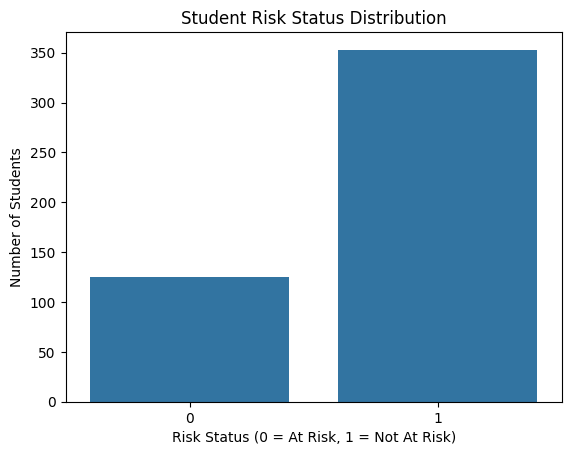

In [6]:
sns.countplot(data=df, x='Risk_Status')

plt.title('Student Risk Status Distribution')
plt.xlabel('Risk Status (0 = At Risk, 1 = Not At Risk)')
plt.ylabel('Number of Students')
plt.show()

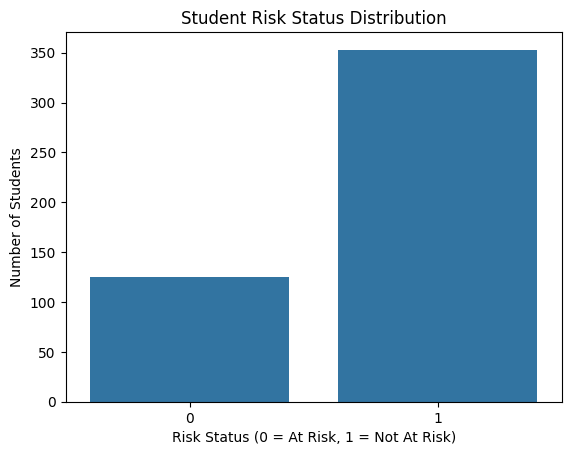

In [7]:
sns.countplot(data=df, x='Risk_Status')

plt.title('Student Risk Status Distribution')
plt.xlabel('Risk Status (0 = At Risk, 1 = Not At Risk)')
plt.ylabel('Number of Students')
plt.show()

In [8]:
X = df.drop(columns=['Class', 'Risk_Status'])

y = df['Risk_Status']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (478, 16)
Target Shape: (478,)


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Records: 382
Testing Records: 96

Training Class Distribution:
Risk_Status
1    282
0    100
Name: count, dtype: int64

Testing Class Distribution:
Risk_Status
1    71
0    25
Name: count, dtype: int64


In [10]:
numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

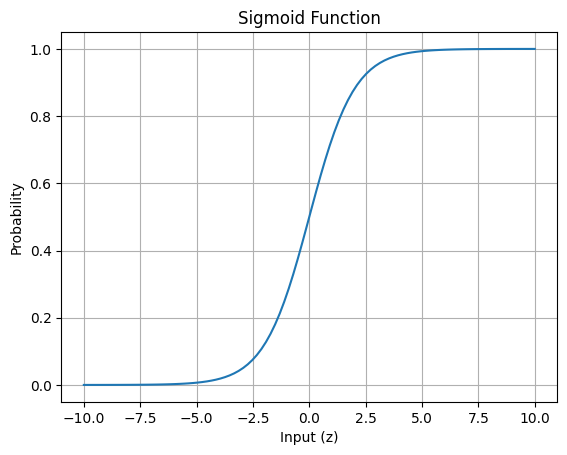

In [11]:
z = np.linspace(-10, 10, 100)

sigmoid = 1 / (1 + np.exp(-z))

plt.plot(z, sigmoid)

plt.title('Sigmoid Function')
plt.xlabel('Input (z)')
plt.ylabel('Probability')
plt.grid()
plt.show()

In [12]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


In [13]:
feature_names = model.named_steps[
    'preprocessor'
].get_feature_names_out()

coefficients = model.named_steps[
    'classifier'
].coef_[0]

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

print("Intercept:",
      model.named_steps['classifier'].intercept_[0])

display(coef_df.sort_values(
    by='Coefficient',
    ascending=False
))

Intercept: 3.4864170793597458


,Feature,Coefficient
69,cat__StudentAbsenceDays_Under-7,1.483277
0,num__raisedhands,0.988642
1,num__VisITedResources,0.948246
38,cat__GradeID_G-06,0.936425
2,num__AnnouncementsView,0.815444
...,...,...
64,cat__ParentAnsweringSurvey_No,-0.606014
16,cat__NationalITy_Tunis,-0.715536
40,cat__GradeID_G-08,-0.940377
50,cat__Topic_Chemistry,-1.468356


In [14]:
y_probability = model.predict_proba(X_test)[:, 1]

y_pred = (y_probability >= 0.5).astype(int)

results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted Probability': y_probability,
    'Predicted Class': y_pred
})

display(results.head(10))

,Actual,Predicted Probability,Predicted Class
0,1,0.998387,1
1,1,0.999785,1
2,1,0.999900,1
3,1,0.944944,1
4,0,0.906291,1
5,1,0.936548,1
6,1,0.999440,1
7,1,0.927925,1
8,1,0.960818,1
9,1,0.999809,1


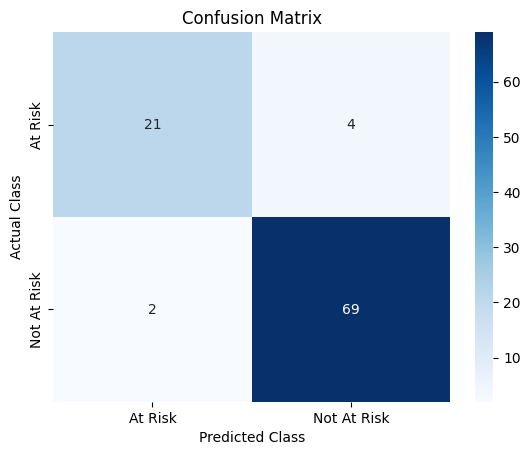

True Negative: 21
False Positive: 4
False Negative: 2
True Positive: 69


In [15]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['At Risk', 'Not At Risk'],
    yticklabels=['At Risk', 'Not At Risk']
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

In [16]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_probability)

metrics_df = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'Specificity',
        'F1 Score',
        'ROC-AUC'
    ],
    'Value': [
        accuracy,
        precision,
        recall,
        specificity,
        f1,
        roc_auc
    ]
})

display(metrics_df)

,Metric,Value
0,Accuracy,0.937500
1,Precision,0.945205
2,Recall,0.971831
3,Specificity,0.840000
4,F1 Score,0.958333
5,ROC-AUC,0.975211


In [17]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['At Risk', 'Not At Risk']
))

              precision    recall  f1-score   support

     At Risk       0.91      0.84      0.88        25
 Not At Risk       0.95      0.97      0.96        71

    accuracy                           0.94        96
   macro avg       0.93      0.91      0.92        96
weighted avg       0.94      0.94      0.94        96



In [18]:
baseline = DummyClassifier(strategy='most_frequent')

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

print("Baseline Accuracy:",
      accuracy_score(y_test, baseline_pred))

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred))

Baseline Accuracy: 0.7395833333333334
Logistic Regression Accuracy: 0.9375


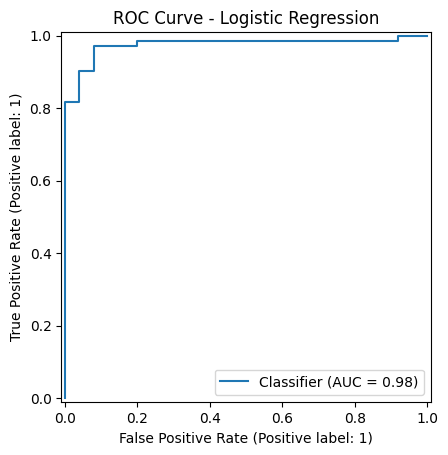

ROC-AUC Score: 0.9752112676056337


In [19]:
RocCurveDisplay.from_predictions(
    y_test,
    y_probability
)

plt.title('ROC Curve - Logistic Regression')
plt.show()

print("ROC-AUC Score:", roc_auc)

In [20]:
thresholds = [0.3, 0.5, 0.7]

threshold_results = []

for threshold in thresholds:

    predictions = (
        y_probability >= threshold
    ).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Predicted Positive': sum(predictions),
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1 Score': f1_score(y_test, predictions)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

,Threshold,Predicted Positive,Accuracy,Precision,Recall,F1 Score
0,0.3,77,0.916667,0.909091,0.985915,0.945946
1,0.5,73,0.937500,0.945205,0.971831,0.958333
2,0.7,71,0.958333,0.971831,0.971831,0.971831


In [21]:
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

print("Training Accuracy:",
      accuracy_score(y_train, train_pred))

print("Testing Accuracy:",
      accuracy_score(y_test, test_pred))

Training Accuracy: 0.9397905759162304
Testing Accuracy: 0.9375


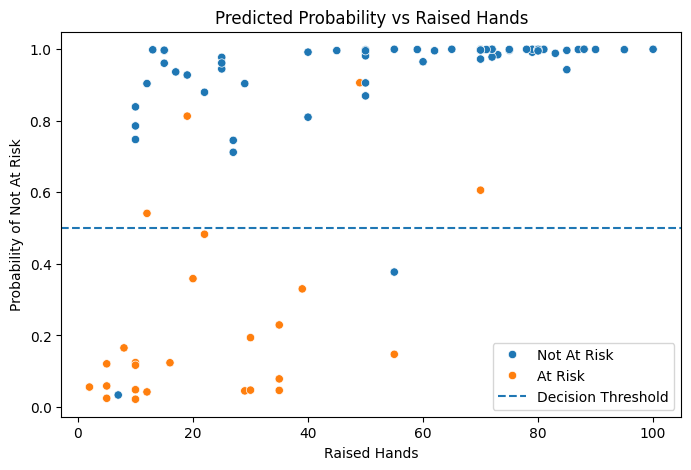

In [22]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_test['raisedhands'],
    y=y_probability,
    hue=y_test.map({
        0: 'At Risk',
        1: 'Not At Risk'
    })
)

plt.axhline(
    0.5,
    linestyle='--',
    label='Decision Threshold'
)

plt.title('Predicted Probability vs Raised Hands')
plt.xlabel('Raised Hands')
plt.ylabel('Probability of Not At Risk')
plt.legend()
plt.show()

In [23]:
new_student = X_test.iloc[[0]]

probability = model.predict_proba(new_student)[0, 1]

prediction = int(probability >= 0.5)

print("Predicted Probability:", probability)

if prediction == 1:
    print("Prediction: Not At Risk")
else:
    print("Prediction: At Risk")

Predicted Probability: 0.9983865315693294
Prediction: Not At Risk


In this activity, a Logistic Regression model was developed to classify students into At Risk and Not At Risk categories using the xAPI-Edu-Data dataset. Data preprocessing included duplicate removal, binary target creation, feature encoding and feature scaling. The dataset was divided into training and testing sets using stratified sampling. The model was evaluated using confusion matrix, accuracy, precision, recall, specificity, F1-score and ROC-AUC. Different decision thresholds were also compared to understand their impact on classification performance. The model can help identify students who may require additional academic support. However, its predictions are probability-based estimates and should not be treated as guaranteed outcomes or used as the sole basis for academic decisions.